<a href="https://colab.research.google.com/github/incrisvel/adaptaste/blob/main/classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip -q install pandas scikit-learn plotly gensim transformers nltk spacy emoji


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 56.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 28.2 MB/s eta 0:00:00


In [2]:
import pandas as pd
import json

# Abre arquivo de reviews
with open('reviews_preprocessed.json', 'r', encoding='utf-8') as f:
    data = json.load(f)

df = pd.DataFrame(data)

## Preparação dos dados

In [3]:
RATING_COLUMN = "rating"

classification_df = df.copy()

classification_df[RATING_COLUMN] = pd.to_numeric(
    classification_df[RATING_COLUMN],
    errors="coerce"
)

# Funil do rótulo: quantas reviews têm nota utilizável antes do filtro
print(f"Reviews no arquivo: {len(classification_df)}")
print(
    "Com nota numérica válida:",
    classification_df[RATING_COLUMN].notna().sum()
)
print(
    "Com nota extrema [1, 2, 4, 5]:",
    classification_df[RATING_COLUMN].isin([1, 2, 4, 5]).sum()
)
print(
    classification_df[RATING_COLUMN]
    .value_counts(dropna=False)
    .sort_index()
)

# Mantém notas extremas e remove notas intermediárias.
classification_df = classification_df[
    classification_df[RATING_COLUMN].isin([1, 2, 4, 5])
].copy()

# Cria rótulos de Positiva (1) e Negativa (0) a partir das classes [1,2] e [4,5]
classification_df["label"] = (
    classification_df[RATING_COLUMN] >= 4
).astype(int)

print(classification_df["label"].value_counts())

if classification_df["label"].nunique() < 2:
    raise ValueError(
        "A base precisa conter exemplos das duas classes."
    )


Reviews no arquivo: 2262
Com nota numérica válida: 2262
Com nota extrema [1, 2, 4, 5]: 2212
rating
1.0      64
2.0      32
3.0      50
4.0     181
5.0    1935
Name: count, dtype: int64
label
1    2116
0      96
Name: count, dtype: int64


In [4]:
# Análise de distribuição das classes
class_counts = classification_df["label"].value_counts().sort_index()

class_summary = pd.DataFrame({
    "quantity": class_counts,
    "proportional": (
        classification_df["label"]
        .value_counts(normalize=True)
        .reindex(class_counts.index)
    )
})

class_summary.index = ["Negativa", "Positiva"]
display(class_summary)

,quantity,proportional
Negativa,96,0.0434
Positiva,2116,0.9566


## Representações textuais × classificadores

O objetivo é responder qual representação textual favorece a classificação. Todas as
representações usam a **mesma divisão** treino/teste, e cada uma entra com dois
classificadores de decisão e duas configurações de `class_weight` (`None` e `balanced`),
para separar o efeito da representação do efeito do desbalanceamento (96 negativas contra
2.116 positivas).

- **BoW**: contagens puras (`CountVectorizer`) sobre `description_lemmatized`.
- **TF-IDF**: mesma entrada, com ponderação IDF (`sublinear_tf`).
- **Word2Vec**: modelo treinado **apenas no split de treino**; documento = média dos vetores.
- **BERT**: embeddings do BERTimbau (*mean pooling*) sobre o **texto original**
  (`description_clean`), sem passar pela lematização do pré-processamento.

Um n-grama só ajuda representação que ignora ordem: BoW e TF-IDF são sacos de contagem e
por isso testam unigramas e uni+bigramas. Word2Vec já aprende a ordem na janela de contexto
e o BERT já é contextual por atenção, então n-gramas nesses dois só aumentariam o
vocabulário sem informação nova.

Para BoW e TF-IDF a vetorização acontece **dentro do `Pipeline`**, e é refeita em cada fold
da validação cruzada. Para Word2Vec e BERT os embeddings são pré-computados sobre o corpus
— limitação declarada no relatório.


In [5]:
from sklearn.model_selection import train_test_split

TEXT_COLUMN = "description_lemmatized"

# Divide os índices uma única vez; cada representação recorta a coluna de que precisa.
train_index, test_index = train_test_split(
    classification_df.index,
    test_size=0.2,
    random_state=42,
    stratify=classification_df["label"]
)

y_train = classification_df.loc[train_index, "label"]
y_test = classification_df.loc[test_index, "label"]

# Tokens (Word2Vec) e texto corrido (vetorizadores de n-gramas)
X_train_tokens = classification_df.loc[train_index, TEXT_COLUMN]
X_test_tokens = classification_df.loc[test_index, TEXT_COLUMN]

X_train_text = X_train_tokens.apply(" ".join)
X_test_text = X_test_tokens.apply(" ".join)

# Texto original, sem lematização, para o BERT
X_train_clean = classification_df.loc[train_index, "description_clean"].tolist()
X_test_clean = classification_df.loc[test_index, "description_clean"].tolist()


In [6]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer


def build_vectorizer(representation, ngram_range):
    # Mesmo tratamento de tokens usado no restante do trabalho.
    common = dict(
        tokenizer=str.split,
        preprocessor=None,
        token_pattern=None,
        ngram_range=ngram_range,
        lowercase=False,
        min_df=1
    )

    if representation == "BoW":
        return CountVectorizer(**common)

    if representation == "TF-IDF":
        return TfidfVectorizer(sublinear_tf=True, **common)

    raise ValueError(f"Representação esparsa desconhecida: {representation}")


In [7]:
import numpy as np
from gensim.models import Word2Vec

# Treinado só com os tokens do treino: o teste não influencia o vocabulário.
w2v_model = Word2Vec(
    sentences=X_train_tokens.tolist(),
    vector_size=190,
    window=5,
    min_count=1,
    sg=1,
    seed=42,
    workers=1,
    epochs=200
)


def w2v_document_vector(tokens):
    # Mesma função de semantic_search.ipynb: média dos vetores conhecidos.
    vectors = [
        w2v_model.wv[token]
        for token in tokens
        if token in w2v_model.wv
    ]

    if not vectors:
        return np.zeros(w2v_model.vector_size, dtype=np.float32)

    return np.mean(vectors, axis=0)


X_train_w2v = np.vstack(X_train_tokens.apply(w2v_document_vector))
X_test_w2v = np.vstack(X_test_tokens.apply(w2v_document_vector))

oov = sum(
    1
    for tokens in X_test_tokens
    for token in tokens
    if token not in w2v_model.wv
)
total = sum(len(tokens) for tokens in X_test_tokens)

print(f"Vocabulário: {len(w2v_model.wv)} tokens")
print(f"OOV no teste: {oov}/{total} ({oov / total:.1%})")


Vocabulário: 2922 tokens
OOV no teste: 353/3148 (11.2%)


In [8]:
import torch
from transformers import AutoModel, AutoTokenizer

BERT_MODEL = "neuralmind/bert-base-portuguese-cased"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

tokenizer_bert = AutoTokenizer.from_pretrained(BERT_MODEL, do_lower_case=False)
bert_model = AutoModel.from_pretrained(BERT_MODEL).to(device)
bert_model.eval()


def mean_pooling(last_hidden_state, attention_mask):
    # Média dos vetores dos tokens, ignorando as posições de padding.
    mask = attention_mask.unsqueeze(-1).expand(
        last_hidden_state.size()
    ).float()
    total = torch.sum(last_hidden_state * mask, dim=1)

    return total / torch.clamp(mask.sum(dim=1), min=1e-9)


def generate_bert_embeddings(texts, batch_size=8):
    embeddings = []

    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]

        inputs = tokenizer_bert(
            batch,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt"
        )
        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        with torch.no_grad():
            output = bert_model(**inputs)

        embeddings.append(
            mean_pooling(
                output.last_hidden_state,
                inputs["attention_mask"]
            ).cpu().numpy()
        )

    return np.vstack(embeddings)


# BERT vê o texto original, não a versão lematizada.
X_train_bert = generate_bert_embeddings(X_train_clean)
X_test_bert = generate_bert_embeddings(X_test_clean)

print("Formato da matriz BERT:", X_train_bert.shape)


Dispositivo: cpu


config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Formato da matriz BERT: (1769, 768)


In [9]:
"""
Grid de experimentos: representação x n-gramas x classificador x class_weight.
Word2Vec e BERT não têm n-gramas: os dois já modelam ordem (janela de contexto e atenção).
"""
SPARSE_REPRESENTATIONS = ["BoW", "TF-IDF"]
NGRAM_RANGES = [(1, 1), (1, 2)]

experiments = [
    {
        "representation": representation,
        "ngram_range": ngram_range,
        "classifier": classifier,
        "class_weight": class_weight
    }
    for representation in ["BoW", "TF-IDF", "Word2Vec", "BERT"]
    for ngram_range in (
        NGRAM_RANGES if representation in SPARSE_REPRESENTATIONS else [None]
    )
    for classifier in ["logistic", "svm"]
    for class_weight in [None, "balanced"]
]

print(f"{len(experiments)} experimentos")


24 experimentos


In [10]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Matrizes densas por representação; as esparsas são vetorizadas dentro do Pipeline.
DENSE_FEATURES = {
    "Word2Vec": (X_train_w2v, X_test_w2v),
    "BERT": (X_train_bert, X_test_bert)
}


def build_model(experiment):
    # Limita número de iterações para classificador logístico
    if experiment["classifier"] == "logistic":
        return LogisticRegression(
            max_iter=1000,
            class_weight=experiment["class_weight"],
            random_state=42
        )

    return LinearSVC(
        class_weight=experiment["class_weight"],
        random_state=42
    )


results = []
fitted_models = {}
experiments_by_name = {}

# Itera sobre os experimentos e treina os modelos
for experiment in experiments:

    representation = experiment["representation"]
    name = " | ".join(
        str(value)
        for value in (
            representation,
            experiment["ngram_range"],
            experiment["classifier"],
            experiment["class_weight"]
        )
    )

    model = build_model(experiment)

    if representation in DENSE_FEATURES:
        # Embeddings já prontos: só o classificador é treinado.
        X_train_fold, X_test_fold = DENSE_FEATURES[representation]
        estimator = model
        estimator.fit(X_train_fold, y_train)
        predictions = estimator.predict(X_test_fold)
    else:
        # Cria pipeline com a representação esparsa
        estimator = Pipeline([
            (
                "vectorizer",
                build_vectorizer(representation, experiment["ngram_range"])
            ),
            ("model", model)
        ])
        estimator.fit(X_train_text, y_train)
        predictions = estimator.predict(X_test_text)

    # Avalia os resultados
    results.append({
        "experiment": name,
        "representation": representation,
        "ngram_range": str(experiment["ngram_range"]),
        "classifier": experiment["classifier"],
        "class_weight": str(experiment["class_weight"]),
        "accuracy": accuracy_score(y_test, predictions),
        "precision_macro": precision_score(
            y_test, predictions,
            average="macro",
            zero_division=0
        ),
        "recall_macro": recall_score(
            y_test, predictions,
            average="macro",
            zero_division=0
        ),
        "f1_macro": f1_score(
            y_test, predictions,
            average="macro",
            zero_division=0
        ),
        "f1_negativa": f1_score(
            y_test, predictions,
            labels=[0],
            average="macro",
            zero_division=0
        ),
        "f1_positiva": f1_score(
            y_test, predictions,
            labels=[1],
            average="macro",
            zero_division=0
        )
    })

    fitted_models[name] = {
        "pipeline": estimator,
        "predictions": predictions,
        "confusion_matrix": confusion_matrix(
            y_test, predictions, labels=[0, 1]
        )
    }

    experiments_by_name[name] = experiment


In [11]:
import pandas as pd

# Converte resultados em dataframe
results_df = pd.DataFrame(results)

# Ranking geral
display(
    results_df
    .sort_values("f1_macro", ascending=False)
    .round(3)
)

# Melhor configuração de cada representação: é o que o item 4 do trabalho pergunta
best = (
    results_df
    .sort_values("f1_macro", ascending=False)
    .groupby("representation", sort=False)
    .head(1)
)

display(best.round(3))

# Efeito do balanceamento e do n-grama no F1 macro
display(
    results_df
    .pivot_table(
        index=["representation", "ngram_range", "classifier"],
        columns="class_weight",
        values="f1_macro"
    )
    .round(3)
    .sort_index()
)


,experiment,representation,ngram_range,classifier,class_weight,accuracy,precision_macro,recall_macro,f1_macro,f1_negativa,f1_positiva
21,BERT | None | logistic | balanced,BERT,None,logistic,balanced,0.980,0.870,0.889,0.879,0.769,0.989
20,BERT | None | logistic | None,BERT,None,logistic,None,0.980,0.949,0.788,0.850,0.710,0.989
22,BERT | None | svm | None,BERT,None,svm,None,0.977,0.944,0.762,0.827,0.667,0.988
23,BERT | None | svm | balanced,BERT,None,svm,balanced,0.973,0.874,0.760,0.805,0.625,0.986
1,"BoW | (1, 1) | logistic | balanced",BoW,"(1, 1)",logistic,balanced,0.971,0.847,0.758,0.795,0.606,0.985
9,"TF-IDF | (1, 1) | logistic | balanced",TF-IDF,"(1, 1)",logistic,balanced,0.964,0.777,0.805,0.791,0.600,0.981
17,Word2Vec | None | logistic | balanced,Word2Vec,None,logistic,balanced,0.955,0.737,0.876,0.788,0.600,0.976
13,"TF-IDF | (1, 2) | logistic | balanced",TF-IDF,"(1, 2)",logistic,balanced,0.968,0.823,0.757,0.786,0.588,0.984
15,"TF-IDF | (1, 2) | svm | balanced",TF-IDF,"(1, 2)",svm,balanced,0.971,0.887,0.708,0.768,0.552,0.985
18,Word2Vec | None | svm | None,Word2Vec,None,svm,None,0.968,0.851,0.707,0.758,0.533,0.984


,experiment,representation,ngram_range,classifier,class_weight,accuracy,precision_macro,recall_macro,f1_macro,f1_negativa,f1_positiva
21,BERT | None | logistic | balanced,BERT,None,logistic,balanced,0.980,0.870,0.889,0.879,0.769,0.989
1,"BoW | (1, 1) | logistic | balanced",BoW,"(1, 1)",logistic,balanced,0.971,0.847,0.758,0.795,0.606,0.985
9,"TF-IDF | (1, 1) | logistic | balanced",TF-IDF,"(1, 1)",logistic,balanced,0.964,0.777,0.805,0.791,0.600,0.981
17,Word2Vec | None | logistic | balanced,Word2Vec,None,logistic,balanced,0.955,0.737,0.876,0.788,0.600,0.976


class_weight                            None  balanced
representation ngram_range classifier                 
BERT           None        logistic    0.850     0.879
                           svm         0.827     0.805
BoW            (1, 1)      logistic    0.700     0.795
                           svm         0.742     0.724
               (1, 2)      logistic    0.585     0.742
                           svm         0.691     0.683
TF-IDF         (1, 1)      logistic    0.489     0.791
                           svm         0.657     0.749
               (1, 2)      logistic    0.489     0.786
                           svm         0.627     0.768
Word2Vec       None        logistic    0.691     0.788
                           svm         0.758     0.754

In [12]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Com 96 negativas no total, um split único é frágil: valida a melhor configuração
# de cada representação em 5 folds estratificados.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []

for name in best["experiment"]:
    experiment = experiments_by_name[name]
    model = build_model(experiment)

    if experiment["representation"] in DENSE_FEATURES:
        X_train_fold, X_test_fold = DENSE_FEATURES[experiment["representation"]]
        X_cv = np.vstack([X_train_fold, X_test_fold])
        estimator = model
    else:
        X_cv = pd.concat([X_train_text, X_test_text])
        estimator = Pipeline([
            (
                "vectorizer",
                build_vectorizer(
                    experiment["representation"],
                    experiment["ngram_range"]
                )
            ),
            ("model", model)
        ])

    y_cv = pd.concat([y_train, y_test])

    scores = cross_val_score(estimator, X_cv, y_cv, cv=cv, scoring="f1_macro")

    cv_results.append({
        "experiment": name,
        "f1_macro_medio": scores.mean(),
        "desvio_padrao": scores.std(),
        "folds": ", ".join(f"{score:.3f}" for score in scores)
    })

display(pd.DataFrame(cv_results).round(3))


,experiment,f1_macro_medio,desvio_padrao,folds
0,BERT | None | logistic | balanced,0.849,0.023,"0.895, 0.831, 0.843, 0.841, 0.833"
1,"BoW | (1, 1) | logistic | balanced",0.798,0.052,"0.797, 0.869, 0.786, 0.710, 0.826"
2,"TF-IDF | (1, 1) | logistic | balanced",0.802,0.031,"0.825, 0.824, 0.817, 0.743, 0.801"
3,Word2Vec | None | logistic | balanced,0.775,0.037,"0.822, 0.759, 0.816, 0.742, 0.737"


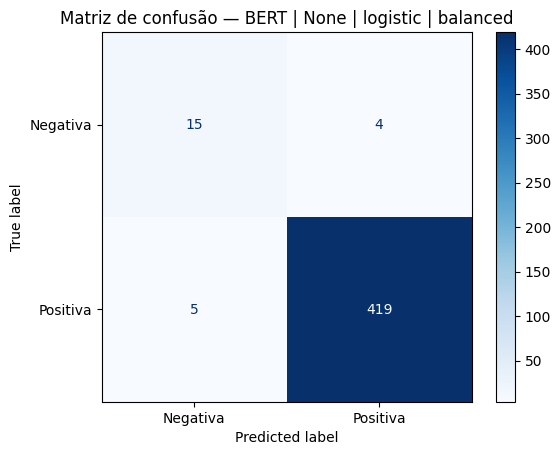

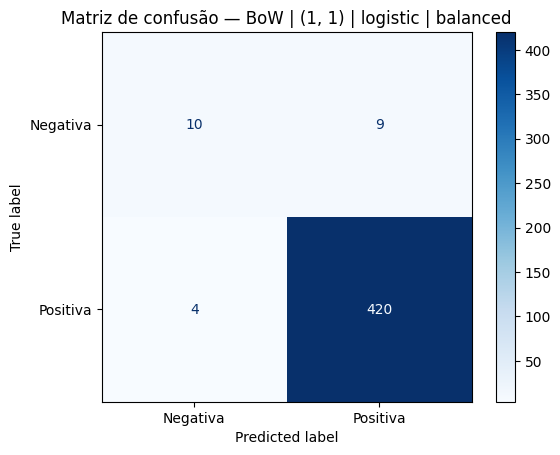

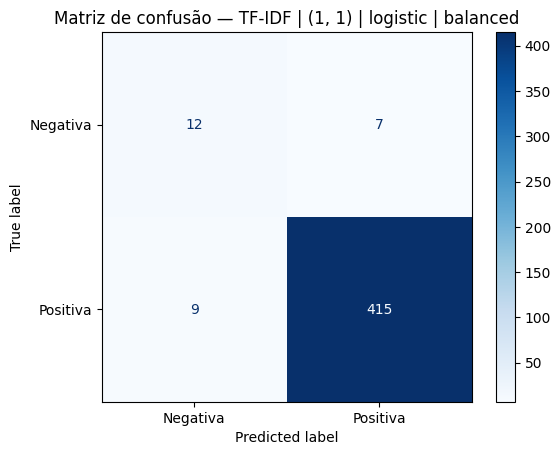

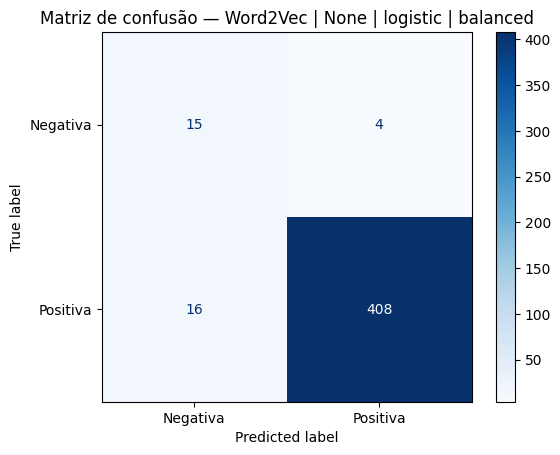

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Uma matriz por representação (a melhor configuração). As 24 não seriam legíveis.
for name in best["experiment"]:
    result = fitted_models[name]

    disp = ConfusionMatrixDisplay(
        confusion_matrix=result["confusion_matrix"],
        display_labels=["Negativa", "Positiva"]
    )

    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Matriz de confusão — {name}")
    plt.show()


## Reviews cruas (dados novos)

As reviews anteriores vêm do arquivo e já estão pré-processadas. Aqui a entrada é **texto
cru**, como chegaria em produção: o rótulo é atribuído manualmente pela equipe (o Google não
expõe nota para essas reviews) e o mesmo pré-processamento de `preprocessing.ipynb` é
aplicado antes de representar.

Reviews de nota 3 não entram nesta avaliação: uma review neutra não é nem positiva nem
negativa, então ela não serve para medir acerto de um classificador binário.


In [14]:
import subprocess
import sys

import emoji
import nltk
import spacy

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

for resource in ("punkt", "punkt_tab", "stopwords"):
    nltk.download(resource, quiet=True)

try:
    nlp = spacy.load("pt_core_news_sm")
except OSError:
    subprocess.run(
        [sys.executable, "-m", "spacy", "download", "pt_core_news_sm"],
        check=True
    )
    nlp = spacy.load("pt_core_news_sm")

# Mesma cadeia de preprocessing.ipynb, para que uma review crua chegue na mesma
# forma de description_lemmatized usada no treino.
preserve_words = {
    # Negação
    "não",
    "nunca",
    "jamais",
    "nem",
    "sem",

    # Intensidade
    "muito",
    "pouco",
    "bastante",
    "demais",

    # Restrição/contraste
    "apenas",
    "só",
    "somente",
    "mas",
    "porém",
    "contudo"
}

stopwords_pt = set(stopwords.words("portuguese")) - preserve_words


def preprocess_review(text):
    cleaned = emoji.replace_emoji(text, replace="")
    tokens = word_tokenize(cleaned, language="portuguese")
    normalized = [
        token.casefold()
        for token in tokens
        if token.isalpha()
    ]
    without_stopwords = [
        token
        for token in normalized
        if token not in stopwords_pt
    ]

    if not without_stopwords:
        return []

    return [
        token.lemma_
        for token in nlp(" ".join(without_stopwords))
        if token.is_alpha
    ]


In [15]:
# Reviews cruas, nunca vistas pelo modelo, com rótulo atribuído pela equipe.
# O sarcasmo entra de propósito: é onde representação de contagem costuma falhar.
new_reviews = pd.DataFrame({
    "review_text": [
        "Comida excelente e atendimento impecável, voltarei sem dúvida.",
        "Demorou mais de uma hora e o prato veio frio. Não volto nunca.",
        "Ambiente bonito, mas o serviço foi lento e caro pelo que entrega.",
        "Que maravilha esperar 40 minutos por um prato frio, adorei.",
        "Preço justo, porções generosas e atendimento atencioso. Recomendo.",
        "Cardápio bonito no site, mas na prática não tinha metade dos pratos."
    ],
    "label_esperado": [1, 0, 0, 0, 1, 0]
})

# Aplica o pré-processamento e representa em cada formato
new_tokens = new_reviews["review_text"].apply(preprocess_review)
new_text = new_tokens.apply(" ".join)
new_clean = new_reviews["review_text"].tolist()

new_predictions = pd.DataFrame({
    "review_text": new_reviews["review_text"].str.slice(0, 70),
    "label_esperado": new_reviews["label_esperado"]
})

for name in best["experiment"]:
    experiment = experiments_by_name[name]

    if experiment["representation"] == "Word2Vec":
        X_new = np.vstack(new_tokens.apply(w2v_document_vector))
    elif experiment["representation"] == "BERT":
        X_new = generate_bert_embeddings(new_clean)
    else:
        X_new = new_text

    new_predictions[name] = fitted_models[name]["pipeline"].predict(X_new)

display(new_predictions)

print("Acertos contra o rótulo manual (de 6):")
print(
    {
        name: int(
            (new_predictions[name] == new_predictions["label_esperado"]).sum()
        )
        for name in best["experiment"]
    }
)


,review_text,label_esperado,BERT | None | logistic | balanced,"BoW | (1, 1) | logistic | balanced","TF-IDF | (1, 1) | logistic | balanced",Word2Vec | None | logistic | balanced
0,"Comida excelente e atendimento impecável, volt...",1,1,1,1,1
1,Demorou mais de uma hora e o prato veio frio. ...,0,0,0,0,0
2,"Ambiente bonito, mas o serviço foi lento e car...",0,0,1,0,1
3,Que maravilha esperar 40 minutos por um prato ...,0,1,0,0,0
4,"Preço justo, porções generosas e atendimento a...",1,1,1,1,1
5,"Cardápio bonito no site, mas na prática não ti...",0,0,0,0,0


Acertos contra o rótulo manual (de 6):
{'BERT | None | logistic | balanced': 5, 'BoW | (1, 1) | logistic | balanced': 5, 'TF-IDF | (1, 1) | logistic | balanced': 6, 'Word2Vec | None | logistic | balanced': 5}


## Conclusões

- Representação com melhor F1 macro: `<preencher após executar>`.
- Sem `class_weight="balanced"` os modelos colapsam na classe majoritária: 0,957 de
  acurácia é exatamente o baseline "tudo positivo" e o F1 da classe negativa cai a zero.
  O ganho vem do balanceamento, não da representação.
- Técnicas utilizadas: **modelo de linguagem** = BERTimbau (embeddings contextuais);
  **modelos de decisão** = Regressão Logística e SVM linear.
- Reviews cruas: acertos contra o rótulo manual e limitação do Word2Vec (tokens fora do
  vocabulário viram vetor nulo).
- Limitação metodológica: os embeddings de Word2Vec e BERT são pré-computados sobre o
  corpus; na validação cruzada o vetorizador de BoW/TF-IDF é refeito a cada fold, os
  embeddings não.
